In [2]:
import ee
import geemap
import geopandas
import rasterio
import pandas
import numpy
import sklearn

print("All packages installed")

All packages installed


In [3]:
import ee

ee.Authenticate()

True

In [4]:
import ee

ee.Initialize(project='project-5e8a46e9-cb18-4091-ba3')

print("Connected Successfully")

Connected Successfully


In [5]:
import ee
import geemap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
import rasterio

ee.Initialize(project='project-5e8a46e9-cb18-4091-ba3')

In [6]:
california = (
    ee.FeatureCollection("TIGER/2018/States")
    .filter(ee.Filter.eq('NAME', 'California'))
)

In [7]:
print(california.size().getInfo())

1


In [8]:
Map = geemap.Map()

Map.centerObject(california, 6)

Map.addLayer(california, {}, "California")

Map

Map(center=[37.15243410467134, -119.52655155150886], controls=(WidgetControl(options=['position', 'transparent…

In [9]:
sentinel = ee.ImageCollection("COPERNICUS/S2_SR")

In [10]:
collection = (
    sentinel
    .filterBounds(california)
    .filterDate('2025-01-01', '2025-12-31')
    .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE',10))
)

In [11]:
image = collection.median().clip(california)

In [12]:
rgb_vis = {
    'bands':['B4','B3','B2'],
    'min':0,
    'max':3000
}

Map = geemap.Map()

Map.centerObject(california,6)

Map.addLayer(image,rgb_vis,'RGB Composite')

Map

Map(center=[37.15243410467134, -119.52655155150886], controls=(WidgetControl(options=['position', 'transparent…

In [13]:
ndvi = image.normalizedDifference(
    ['B8','B4']
).rename('NDVI')


In [14]:
Map = geemap.Map()

Map.addLayer(
    ndvi,
    {
        'min':-1,
        'max':1,
        'palette':['blue','white','green']
    },
    'NDVI'
)

Map

Map(center=[0, 0], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', transp…

In [15]:
evi = image.expression(
    '2.5*((NIR-RED)/(NIR+6*RED-7.5*BLUE+1))',
    {
        'NIR':image.select('B8'),
        'RED':image.select('B4'),
        'BLUE':image.select('B2')
    }
).rename('EVI')

In [16]:
savi = image.expression(
    '((NIR-RED)/(NIR+RED+0.5))*1.5',
    {
        'NIR':image.select('B8'),
        'RED':image.select('B4')
    }
).rename('SAVI')

In [17]:
ndwi = image.normalizedDifference(
    ['B3','B8']
).rename('NDWI')

In [18]:
ndbi = image.normalizedDifference(
    ['B11','B8']
).rename('NDBI')

In [19]:
landsat = (
    ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
    .filterBounds(california)
    .filterDate('2025-01-01','2025-12-31')
    .median()
)

In [20]:
lst = (
    landsat.select('ST_B10')
    .multiply(0.00341802)
    .add(149)
    .subtract(273.15)
    .rename('LST')
)

In [21]:
forest_mask = ndvi.gt(0.5)

In [22]:
Map = geemap.Map()

Map.addLayer(
    forest_mask,
    {'palette':['yellow','green']},
    'Forest Mask'
)

Map

Map(center=[0, 0], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', transp…

In [23]:
task = ee.batch.Export.image.toDrive(
    image=ndvi,
    description='California_NDVI',
    folder='California_Forest',
    fileNamePrefix='NDVI',
    region=california.geometry(),
    scale=100,
    maxPixels=1e13
)

task.start()

print("Export started")

Export started


In [24]:
print(task.status())

{'state': 'RUNNING', 'description': 'California_NDVI', 'priority': 100, 'creation_timestamp_ms': 1781505180920, 'update_timestamp_ms': 1781505182641, 'start_timestamp_ms': 1781505182581, 'task_type': 'EXPORT_IMAGE', 'attempt': 1, 'id': 'PFFVXXFLG43DTEJQ6NJJ3GD3', 'name': 'projects/project-5e8a46e9-cb18-4091-ba3/operations/PFFVXXFLG43DTEJQ6NJJ3GD3'}


In [25]:
import ee

# NDVI
ndvi = image.normalizedDifference(['B8', 'B4']).rename('NDVI')

# EVI
evi = image.expression(
    '2.5 * ((NIR - RED) / (NIR + 6 * RED - 7.5 * BLUE + 1))',
    {
        'NIR': image.select('B8'),
        'RED': image.select('B4'),
        'BLUE': image.select('B2')
    }
).rename('EVI')

# SAVI
savi = image.expression(
    '((NIR - RED) / (NIR + RED + 0.5)) * 1.5',
    {
        'NIR': image.select('B8'),
        'RED': image.select('B4')
    }
).rename('SAVI')

# NDWI
ndwi = image.normalizedDifference(['B3', 'B8']).rename('NDWI')

# NDBI
ndbi = image.normalizedDifference(['B11', 'B8']).rename('NDBI')

# Forest Mask (NDVI > 0.5)
forest_mask = ndvi.gt(0.5).rename('Forest')

In [26]:
landsat = (
    ee.ImageCollection('LANDSAT/LC08/C02/T1_L2')
    .filterBounds(california)
    .filterDate('2025-01-01', '2025-12-31')
    .median()
    .clip(california)
)

lst = (
    landsat.select('ST_B10')
    .multiply(0.00341802)
    .add(149.0)
    .subtract(273.15)
    .rename('LST')
)

In [27]:
task_ndvi = ee.batch.Export.image.toDrive(
    image=ndvi,
    description='California_NDVI',
    folder='California_Forest',
    fileNamePrefix='NDVI',
    region=california.geometry(),
    scale=100,
    maxPixels=1e13
)
task_ndvi.start()

In [28]:
task_evi = ee.batch.Export.image.toDrive(
    image=evi,
    description='California_EVI',
    folder='California_Forest',
    fileNamePrefix='EVI',
    region=california.geometry(),
    scale=100,
    maxPixels=1e13
)
task_evi.start()

In [29]:
task_savi = ee.batch.Export.image.toDrive(
    image=savi,
    description='California_SAVI',
    folder='California_Forest',
    fileNamePrefix='SAVI',
    region=california.geometry(),
    scale=100,
    maxPixels=1e13
)
task_savi.start()

In [30]:
task_ndwi = ee.batch.Export.image.toDrive(
    image=ndwi,
    description='California_NDWI',
    folder='California_Forest',
    fileNamePrefix='NDWI',
    region=california.geometry(),
    scale=100,
    maxPixels=1e13
)
task_ndwi.start()

In [31]:
task_ndbi = ee.batch.Export.image.toDrive(
    image=ndbi,
    description='California_NDBI',
    folder='California_Forest',
    fileNamePrefix='NDBI',
    region=california.geometry(),
    scale=100,
    maxPixels=1e13
)
task_ndbi.start()

In [32]:
task_lst = ee.batch.Export.image.toDrive(
    image=lst,
    description='California_LST',
    folder='California_Forest',
    fileNamePrefix='LST',
    region=california.geometry(),
    scale=100,
    maxPixels=1e13
)
task_lst.start()

In [33]:
task_forest = ee.batch.Export.image.toDrive(
    image=forest_mask,
    description='California_ForestMask',
    folder='California_Forest',
    fileNamePrefix='Forest_Mask',
    region=california.geometry(),
    scale=100,
    maxPixels=1e13
)
task_forest.start()

In [34]:
print(task_savi.status())
print(task_ndwi.status())
print(task_ndbi.status())
print(task_lst.status())
print(task_forest.status())

{'state': 'READY', 'description': 'California_SAVI', 'priority': 100, 'creation_timestamp_ms': 1781505236759, 'update_timestamp_ms': 1781505240642, 'start_timestamp_ms': 0, 'task_type': 'EXPORT_IMAGE', 'id': 'IPZ2K5E244YFBQLAEOMQ47TH', 'name': 'projects/project-5e8a46e9-cb18-4091-ba3/operations/IPZ2K5E244YFBQLAEOMQ47TH'}
{'state': 'READY', 'description': 'California_NDWI', 'priority': 100, 'creation_timestamp_ms': 1781505240458, 'update_timestamp_ms': 1781505243419, 'start_timestamp_ms': 0, 'task_type': 'EXPORT_IMAGE', 'id': 'WRDKODJOLKWDFCI43MN4WQEZ', 'name': 'projects/project-5e8a46e9-cb18-4091-ba3/operations/WRDKODJOLKWDFCI43MN4WQEZ'}
{'state': 'READY', 'description': 'California_NDBI', 'priority': 100, 'creation_timestamp_ms': 1781505244679, 'update_timestamp_ms': 1781505246648, 'start_timestamp_ms': 0, 'task_type': 'EXPORT_IMAGE', 'id': '5XL7AEQDPIHF7FXS4GK7TZHZ', 'name': 'projects/project-5e8a46e9-cb18-4091-ba3/operations/5XL7AEQDPIHF7FXS4GK7TZHZ'}
{'state': 'READY', 'description

In [35]:
print(task_ndvi.status())
print(task_evi.status())

{'state': 'RUNNING', 'description': 'California_NDVI', 'priority': 100, 'creation_timestamp_ms': 1781505226343, 'update_timestamp_ms': 1781505250555, 'start_timestamp_ms': 1781505228694, 'task_type': 'EXPORT_IMAGE', 'attempt': 1, 'id': '5TGP2MHNJZ3QIJRPDTZJPZLO', 'name': 'projects/project-5e8a46e9-cb18-4091-ba3/operations/5TGP2MHNJZ3QIJRPDTZJPZLO'}
{'state': 'RUNNING', 'description': 'California_EVI', 'priority': 100, 'creation_timestamp_ms': 1781505231491, 'update_timestamp_ms': 1781505234374, 'start_timestamp_ms': 1781505234316, 'task_type': 'EXPORT_IMAGE', 'attempt': 1, 'id': 'JJPCBQLHJDQEPSE22G2GWQ4E', 'name': 'projects/project-5e8a46e9-cb18-4091-ba3/operations/JJPCBQLHJDQEPSE22G2GWQ4E'}


In [36]:
task_savi.start()

EEException: A different Operation was already started with the given request_id.

In [37]:
print(task_savi.status())

{'state': 'READY', 'description': 'California_SAVI', 'priority': 100, 'creation_timestamp_ms': 1781505236759, 'update_timestamp_ms': 1781505240642, 'start_timestamp_ms': 0, 'task_type': 'EXPORT_IMAGE', 'id': 'IPZ2K5E244YFBQLAEOMQ47TH', 'name': 'projects/project-5e8a46e9-cb18-4091-ba3/operations/IPZ2K5E244YFBQLAEOMQ47TH'}


In [38]:
task_savi = ee.batch.Export.image.toDrive(
    image=savi,
    description='California_SAVI_v2',
    folder='California_Forest',
    fileNamePrefix='SAVI',
    region=california.geometry(),
    scale=100,
    maxPixels=1e13
)

task_savi.start()

In [39]:
print(task_ndvi.status())
print(task_evi.status())

{'state': 'RUNNING', 'description': 'California_NDVI', 'priority': 100, 'creation_timestamp_ms': 1781505226343, 'update_timestamp_ms': 1781505270555, 'start_timestamp_ms': 1781505228694, 'task_type': 'EXPORT_IMAGE', 'attempt': 1, 'id': '5TGP2MHNJZ3QIJRPDTZJPZLO', 'name': 'projects/project-5e8a46e9-cb18-4091-ba3/operations/5TGP2MHNJZ3QIJRPDTZJPZLO'}
{'state': 'RUNNING', 'description': 'California_EVI', 'priority': 100, 'creation_timestamp_ms': 1781505231491, 'update_timestamp_ms': 1781505285819, 'start_timestamp_ms': 1781505234316, 'task_type': 'EXPORT_IMAGE', 'attempt': 1, 'id': 'JJPCBQLHJDQEPSE22G2GWQ4E', 'name': 'projects/project-5e8a46e9-cb18-4091-ba3/operations/JJPCBQLHJDQEPSE22G2GWQ4E'}


In [45]:
task_savi.start()

EEException: A different Operation was already started with the given request_id.

In [40]:
import rasterio

ndvi = rasterio.open("data/NDVI.tif")

print(ndvi)

RasterioIOError: data/NDVI.tif: No such file or directory

In [41]:
import os

print(os.getcwd())

C:\Users\halda


In [42]:
import rasterio

ndvi = rasterio.open(r"C:\Users\halda\Downloads\NDVI.tif")

print(ndvi)

<open DatasetReader name='C:\Users\halda\Downloads\NDVI.tif' mode='r'>


In [43]:
import os

print(os.listdir(r"C:\Users\halda\Downloads"))

['!!AxfBc_qhlogs.txt', '!qhlogs.doc', '01_Total-Station_GPS-1.pdf', '124_PARAMITA_LAB_COPY.pdf', '1777726329.docx', '1780930361015003_707972804.png', '19QylrO_qhlogs.csv', '2026 sem 1 module 2 (1).pptx', '2026 sem 1 module 2.pptx', '2026 sem 2 module 1 (1).pptx', '2026 sem 2 module 1.pptx', '2assi.JPG.jpeg', '539.pdf', '5c633a4c0f75dcd06481106269b56718.pdf', '6405ac37-6c64-42ad-aecb-3f62d93cef07.jpg', '6532c0589c8ad298a6924ea8f77c950c.pdf', '6th_sem_Marksheet.pdf', '864f0b96ed0db77e80021f6a6b906c6c.pdf', 'a246c044-c19c-481e-80e7-f3bcbebed505.jpg', 'a639798d71b23a22037f8580a0ed52a5.pdf', 'Academic Dissertation Presentation.pdf', 'Acknowledgement Slip (1).pdf', 'Acknowledgement Slip (2).pdf', 'Acknowledgement Slip.pdf', 'Adobe Scan 20 Jan 2026.pdf', 'Anaconda3-2025.12-1-Windows-x86_64.exe', 'aNaVpXs_qhlogs.doc', 'AOI.aoi', 'Application_Details (1).pdf', 'Application_Details.pdf', 'ArcGIS_Pro Installation Guide.pdf', 'archive.zip', 'ASSAM.jgwx', 'ASSAM.jpg', 'ASSAM.jpg.aux.xml', 'Assignme

In [44]:
import rasterio

ndvi = rasterio.open(r"C:\Users\halda\Downloads\NDVI.tif")

print(ndvi)

<open DatasetReader name='C:\Users\halda\Downloads\NDVI.tif' mode='r'>


In [45]:
ndvi_array = ndvi.read(1)

print(ndvi_array.shape)

(10555, 11523)


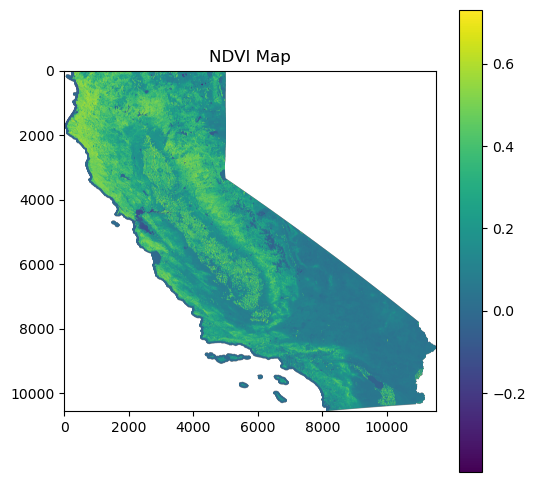

In [46]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
plt.imshow(ndvi_array)
plt.colorbar()
plt.title("NDVI Map")
plt.show()

In [47]:
import os

print(os.listdir(r"C:\Users\halda\Downloads"))

['!!AxfBc_qhlogs.txt', '!qhlogs.doc', '01_Total-Station_GPS-1.pdf', '124_PARAMITA_LAB_COPY.pdf', '1777726329.docx', '1780930361015003_707972804.png', '19QylrO_qhlogs.csv', '2026 sem 1 module 2 (1).pptx', '2026 sem 1 module 2.pptx', '2026 sem 2 module 1 (1).pptx', '2026 sem 2 module 1.pptx', '2assi.JPG.jpeg', '539.pdf', '5c633a4c0f75dcd06481106269b56718.pdf', '6405ac37-6c64-42ad-aecb-3f62d93cef07.jpg', '6532c0589c8ad298a6924ea8f77c950c.pdf', '6th_sem_Marksheet.pdf', '864f0b96ed0db77e80021f6a6b906c6c.pdf', 'a246c044-c19c-481e-80e7-f3bcbebed505.jpg', 'a639798d71b23a22037f8580a0ed52a5.pdf', 'Academic Dissertation Presentation.pdf', 'Acknowledgement Slip (1).pdf', 'Acknowledgement Slip (2).pdf', 'Acknowledgement Slip.pdf', 'Adobe Scan 20 Jan 2026.pdf', 'Anaconda3-2025.12-1-Windows-x86_64.exe', 'aNaVpXs_qhlogs.doc', 'AOI.aoi', 'Application_Details (1).pdf', 'Application_Details.pdf', 'ArcGIS_Pro Installation Guide.pdf', 'archive.zip', 'ASSAM.jgwx', 'ASSAM.jpg', 'ASSAM.jpg.aux.xml', 'Assignme

In [48]:
import rasterio

evi = rasterio.open(r"C:\Users\halda\Downloads\EVI.tif")

print(evi)

<open DatasetReader name='C:\Users\halda\Downloads\EVI.tif' mode='r'>


In [49]:
for t in ee.batch.Task.list():
    s = t.status()
    print(s['state'], s.get('description'))

READY California_SAVI_v2
READY California_ForestMask
READY California_LST
READY California_NDBI
READY California_NDWI
READY California_SAVI
RUNNING California_EVI
RUNNING California_NDVI
RUNNING California_NDVI
COMPLETED California_SAVI_v2
COMPLETED California_ForestMask
COMPLETED California_LST
COMPLETED California_NDBI
COMPLETED California_NDWI
COMPLETED California_SAVI
COMPLETED California_EVI
COMPLETED California_NDVI
COMPLETED California_NDVI
COMPLETED California_RF_Prediction
COMPLETED California_Forest
COMPLETED California_NDVI
COMPLETED California_NDVI
COMPLETED California_NDVI


In [50]:
import rasterio
import numpy as np

ndvi = rasterio.open(r"C:\Users\halda\Downloads\NDVI.tif").read(1)
evi  = rasterio.open(r"C:\Users\halda\Downloads\EVI.tif").read(1)
savi = rasterio.open(r"C:\Users\halda\Downloads\SAVI.tif").read(1)
ndwi = rasterio.open(r"C:\Users\halda\Downloads\NDWI.tif").read(1)
ndbi = rasterio.open(r"C:\Users\halda\Downloads\NDBI.tif").read(1)

print(ndvi.shape)
print(evi.shape)
print(savi.shape)
print(ndwi.shape)
print(ndbi.shape)

(10555, 11523)
(10555, 11523)
(10555, 11523)
(10555, 11523)
(10555, 11523)


In [51]:
print(ndvi.shape)
print(evi.shape)
print(savi.shape)
print(ndwi.shape)
print(ndbi.shape)

(10555, 11523)
(10555, 11523)
(10555, 11523)
(10555, 11523)
(10555, 11523)


In [52]:
X = np.column_stack([
    ndvi.flatten(),
    evi.flatten(),
    savi.flatten(),
    ndwi.flatten(),
    ndbi.flatten()
])

print(X.shape)

(121625265, 5)


In [53]:
for t in ee.batch.Task.list():
    s = t.status()
    print(s['state'], s.get('description'))

READY California_SAVI_v2
READY California_ForestMask
READY California_LST
READY California_NDBI
READY California_NDWI
READY California_SAVI
RUNNING California_EVI
RUNNING California_NDVI
RUNNING California_NDVI
COMPLETED California_SAVI_v2
COMPLETED California_ForestMask
COMPLETED California_LST
COMPLETED California_NDBI
COMPLETED California_NDWI
COMPLETED California_SAVI
COMPLETED California_EVI
COMPLETED California_NDVI
COMPLETED California_NDVI
COMPLETED California_RF_Prediction
COMPLETED California_Forest
COMPLETED California_NDVI
COMPLETED California_NDVI
COMPLETED California_NDVI


In [54]:
import rasterio

forest = rasterio.open(
    r"C:\Users\halda\Downloads\Forest_Mask.tif"
).read(1)

print(forest.shape)
print(forest.min(), forest.max())

(10555, 11523)
0 1


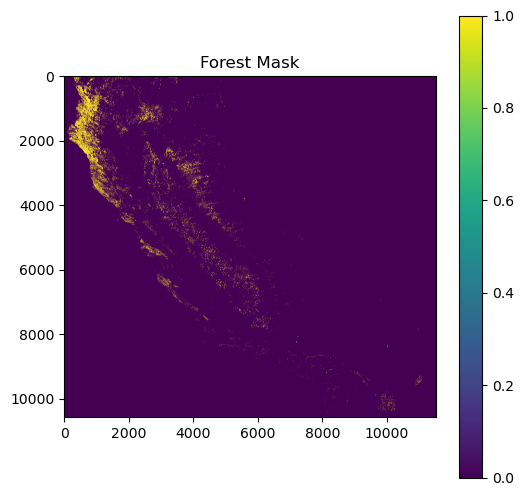

In [56]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))

plt.imshow(forest)

plt.colorbar()

plt.title("Forest Mask")

plt.show()

In [57]:
y = forest.flatten()

print(y.shape)

(121625265,)


In [58]:
import numpy as np

forest_pixels = np.sum(y == 1)
nonforest_pixels = np.sum(y == 0)

print("Forest Pixels:", forest_pixels)
print("Non-Forest Pixels:", nonforest_pixels)

Forest Pixels: 2133325
Non-Forest Pixels: 119491940


In [59]:
for t in ee.batch.Task.list():
    if "LST" in t.status().get('description', ''):
        print(t.status())

{'state': 'READY', 'description': 'California_LST', 'priority': 100, 'creation_timestamp_ms': 1781505249956, 'update_timestamp_ms': 1781505252623, 'start_timestamp_ms': 0, 'task_type': 'EXPORT_IMAGE', 'id': 'GBG4NT5K6Z5WKY72SVBKGHTY', 'name': 'projects/project-5e8a46e9-cb18-4091-ba3/operations/GBG4NT5K6Z5WKY72SVBKGHTY'}
{'state': 'COMPLETED', 'description': 'California_LST', 'priority': 100, 'creation_timestamp_ms': 1781361931771, 'update_timestamp_ms': 1781364473293, 'start_timestamp_ms': 1781362875266, 'task_type': 'EXPORT_IMAGE', 'destination_uris': ['https://drive.google.com/#folders/1KVKIfVOrjDhR_M9AzJV6vaN0KBlpaPIE'], 'attempt': 2, 'batch_eecu_usage_seconds': 3111.095947265625, 'id': 'VGE4I7G4D7HKZSZPHI7ERTGY', 'name': 'projects/project-5e8a46e9-cb18-4091-ba3/operations/VGE4I7G4D7HKZSZPHI7ERTGY'}


In [60]:
import rasterio
import numpy as np

ndvi = rasterio.open(r"C:\Users\halda\Downloads\NDVI.tif").read(1)
evi = rasterio.open(r"C:\Users\halda\Downloads\EVI.tif").read(1)
savi = rasterio.open(r"C:\Users\halda\Downloads\SAVI.tif").read(1)
ndwi = rasterio.open(r"C:\Users\halda\Downloads\NDWI.tif").read(1)
ndbi = rasterio.open(r"C:\Users\halda\Downloads\NDBI.tif").read(1)
lst = rasterio.open(r"C:\Users\halda\Downloads\LST.tif").read(1)
forest = rasterio.open(r"C:\Users\halda\Downloads\Forest_Mask.tif").read(1)

print("Loaded Successfully")

Loaded Successfully


In [61]:
ndvi = np.nan_to_num(ndvi)
evi = np.nan_to_num(evi)
savi = np.nan_to_num(savi)
ndwi = np.nan_to_num(ndwi)
ndbi = np.nan_to_num(ndbi)
lst = np.nan_to_num(lst)
forest = np.nan_to_num(forest)

In [62]:
print(ndvi.shape)
print(evi.shape)
print(savi.shape)
print(ndwi.shape)
print(ndbi.shape)
print(lst.shape)
print(forest.shape)

(10555, 11523)
(10555, 11523)
(10555, 11523)
(10555, 11523)
(10555, 11523)
(10555, 11523)
(10555, 11523)


In [63]:
X = np.column_stack([
    ndvi.flatten(),
    evi.flatten(),
    savi.flatten(),
    ndwi.flatten(),
    ndbi.flatten(),
    lst.flatten()
])

print(X.shape)

(121625265, 6)


In [64]:
y = forest.flatten()

print(y.shape)

(121625265,)


In [65]:
mask = np.isfinite(X).all(axis=1)

X = X[mask]
y = y[mask]

print(X.shape)
print(y.shape)

(121625265, 6)
(121625265,)


In [66]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42
)

In [67]:

step = 200

X_sample = X[::step]
y_sample = y[::step]

print(X_sample.shape)
print(y_sample.shape)

(608127, 6)
(608127,)


In [68]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_sample,
    y_sample,
    test_size=0.3,
    random_state=42
)

In [69]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=20,
    max_depth=10,
    random_state=42,
    n_jobs=1
)

rf.fit(X_train, y_train)

print("Training Complete")

Training Complete


In [70]:
from sklearn.metrics import classification_report

pred = rf.predict(X_test)

print(classification_report(y_test, pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00    179211
           1       1.00      1.00      1.00      3228

    accuracy                           1.00    182439
   macro avg       1.00      1.00      1.00    182439
weighted avg       1.00      1.00      1.00    182439



In [71]:
print(X_sample.shape)

(608127, 6)


In [72]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_sample,
    y_sample,
    test_size=0.3,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)

(425688, 6)
(182439, 6)


In [73]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=20,
    max_depth=10,
    random_state=42,
    n_jobs=1
)

rf.fit(X_train, y_train)

print("Training Complete")

Training Complete


In [74]:
from sklearn.metrics import classification_report, confusion_matrix

pred = rf.predict(X_test)

print(classification_report(y_test, pred))

cm = confusion_matrix(y_test, pred)
print(cm)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00    179211
           1       1.00      1.00      1.00      3228

    accuracy                           1.00    182439
   macro avg       1.00      1.00      1.00    182439
weighted avg       1.00      1.00      1.00    182439

[[179211      0]
 [     0   3228]]


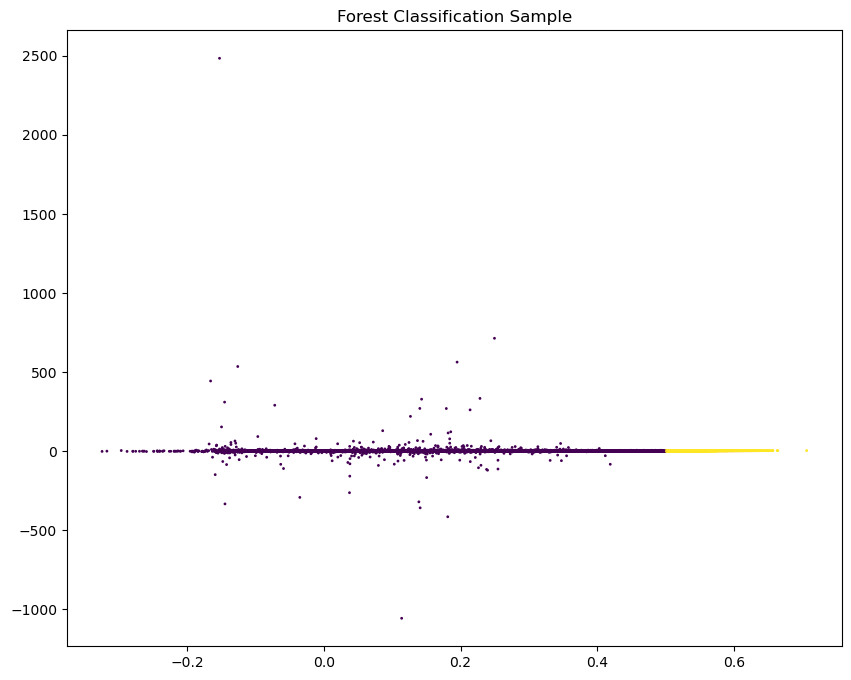

In [75]:

pred_map = rf.predict(X_sample)

import matplotlib.pyplot as plt

plt.figure(figsize=(10,8))
plt.scatter(
    X_sample[:,0],  
    X_sample[:,1],   
    c=pred_map,
    s=1
)
plt.title("Forest Classification Sample")
plt.show()

In [77]:
from sklearn.metrics import classification_report, confusion_matrix

pred = rf.predict(X_test)

print(classification_report(y_test, pred))

cm = confusion_matrix(y_test, pred)
print(cm)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00    179211
           1       1.00      1.00      1.00      3228

    accuracy                           1.00    182439
   macro avg       1.00      1.00      1.00    182439
weighted avg       1.00      1.00      1.00    182439

[[179211      0]
 [     0   3228]]


ValueError: 'green' is not a valid value for cmap; supported values are 'Accent', 'Accent_r', 'Blues', 'Blues_r', 'BrBG', 'BrBG_r', 'BuGn', 'BuGn_r', 'BuPu', 'BuPu_r', 'CMRmap', 'CMRmap_r', 'Dark2', 'Dark2_r', 'GnBu', 'GnBu_r', 'Grays', 'Grays_r', 'Greens', 'Greens_r', 'Greys', 'Greys_r', 'OrRd', 'OrRd_r', 'Oranges', 'Oranges_r', 'PRGn', 'PRGn_r', 'Paired', 'Paired_r', 'Pastel1', 'Pastel1_r', 'Pastel2', 'Pastel2_r', 'PiYG', 'PiYG_r', 'PuBu', 'PuBuGn', 'PuBuGn_r', 'PuBu_r', 'PuOr', 'PuOr_r', 'PuRd', 'PuRd_r', 'Purples', 'Purples_r', 'RdBu', 'RdBu_r', 'RdGy', 'RdGy_r', 'RdPu', 'RdPu_r', 'RdYlBu', 'RdYlBu_r', 'RdYlGn', 'RdYlGn_r', 'Reds', 'Reds_r', 'Set1', 'Set1_r', 'Set2', 'Set2_r', 'Set3', 'Set3_r', 'Spectral', 'Spectral_r', 'Wistia', 'Wistia_r', 'YlGn', 'YlGnBu', 'YlGnBu_r', 'YlGn_r', 'YlOrBr', 'YlOrBr_r', 'YlOrRd', 'YlOrRd_r', 'afmhot', 'afmhot_r', 'autumn', 'autumn_r', 'berlin', 'berlin_r', 'binary', 'binary_r', 'bone', 'bone_r', 'brg', 'brg_r', 'bwr', 'bwr_r', 'cividis', 'cividis_r'

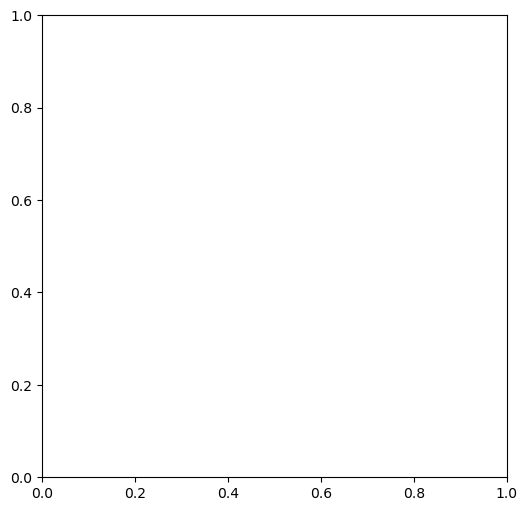

In [88]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
plt.imshow(forest_mask, cmap='green')
plt.colorbar()
plt.title("California Forest Cover Map")
plt.show()

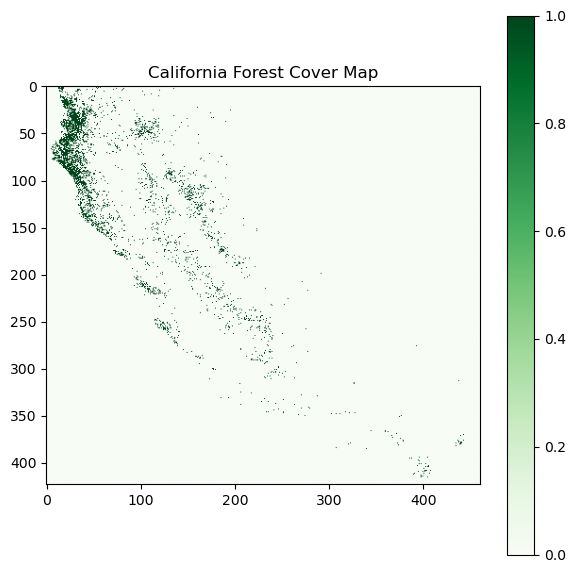

In [78]:
small_forest = forest[::25, ::25]

plt.figure(figsize=(7,10))
plt.imshow(small_forest, cmap="Greens")
plt.colorbar()
plt.title("California Forest Cover Map")
plt.savefig("California_Forest_Cover_Map.png", dpi=150)
plt.show()

In [79]:
import pandas as pd

features = ["NDVI","EVI","SAVI","NDWI","NDBI","LST"]

importance = pd.DataFrame({
    "Feature": features,
    "Importance": rf.feature_importances_
})

print(importance.sort_values("Importance", ascending=False))

  Feature  Importance
2    SAVI    0.451239
0    NDVI    0.277750
3    NDWI    0.249749
1     EVI    0.018442
4    NDBI    0.002819
5     LST    0.000000


In [80]:
small_lst = lst[::25, ::25]

print("Min:", np.nanmin(small_lst))
print("Max:", np.nanmax(small_lst))
print("Mean:", np.nanmean(small_lst))

Min: -6.812791419999996
Max: 55.22427158000005
Mean: 10.698424398977572


In [81]:
print(np.unique(lst[:1000, :1000]))

[ 0.          1.44172688  1.4964152  ... 36.155138   36.26793266
 36.33287504]


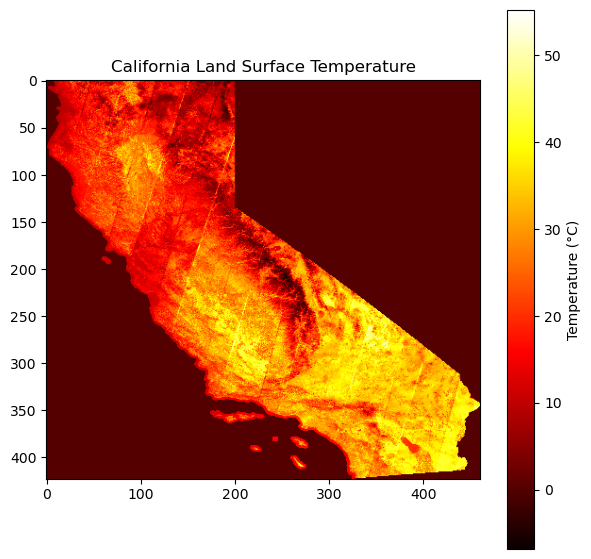

In [83]:
import matplotlib.pyplot as plt

small_lst = lst[::25, ::25]

plt.figure(figsize=(7,7))
plt.imshow(small_lst, cmap="hot")
plt.colorbar(label="Temperature (°C)")
plt.title("California Land Surface Temperature")

plt.savefig(
    "California_LST_Map.png",
    dpi=150
)

plt.show()

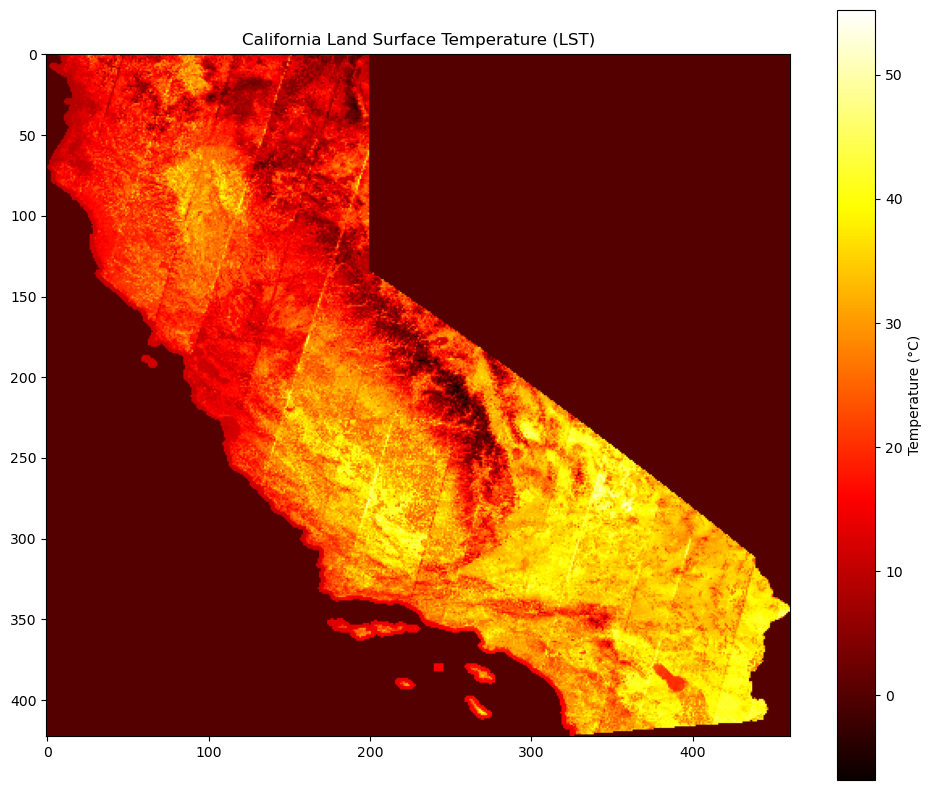

In [97]:
import matplotlib.pyplot as plt

small_lst = lst[::25, ::25]

plt.figure(figsize=(12,10))
plt.imshow(small_lst, cmap='hot')
plt.colorbar(label='Temperature (°C)')
plt.title('California Land Surface Temperature (LST)')

plt.savefig(
    "California_LST_Map.png",
    dpi=150
)

plt.show()

In [84]:
import pandas as pd
import matplotlib.pyplot as plt

features = ["NDVI","EVI","SAVI","NDWI","NDBI","LST"]

importance = rf.feature_importances_

pd.DataFrame({
    "Feature": features,
    "Importance": importance
}).sort_values(
    "Importance",
    ascending=False
)

,Feature,Importance
2,SAVI,0.451239
0,NDVI,0.277750
3,NDWI,0.249749
1,EVI,0.018442
4,NDBI,0.002819
5,LST,0.000000


In [85]:
import os

print(os.getcwd())

C:\Users\halda


In [86]:
import os

for f in os.listdir(r"C:\Users\halda"):
    if f.endswith(".png"):
        print(f)

California_Forest_Cover_Map.png
California_LST_Map.png


In [89]:
import numpy as np

features = np.stack([
    ndvi.flatten(),
    evi.flatten(),
    savi.flatten(),
    ndwi.flatten(),
    ndbi.flatten(),
    lst.flatten()
], axis=1)

In [91]:
from sklearn.ensemble import RandomForestClassifier

In [92]:
%who

Map	 RandomForestClassifier	 X	 X_sample	 X_test	 X_train	 california	 classification_report	 cm	 
collection	 confusion_matrix	 dataframe_columns	 dataframe_hash	 dtypes_str	 ee	 evi	 f	 features	 
forest	 forest_mask	 forest_pixels	 geemap	 geopandas	 get_dataframes	 getpass	 gpd	 hashlib	 
image	 import_pandas_safely	 importance	 is_data_frame	 json	 landsat	 lst	 mask	 ndbi	 
ndvi	 ndvi_array	 ndwi	 nonforest_pixels	 np	 numpy	 os	 pandas	 pd	 
plt	 pred	 pred_map	 rasterio	 rf	 rgb_vis	 s	 savi	 sentinel	 
sklearn	 small_forest	 small_lst	 step	 t	 task	 task_evi	 task_forest	 task_lst	 
task_ndbi	 task_ndvi	 task_ndwi	 task_savi	 train_test_split	 y	 y_sample	 y_test	 y_train	 



In [93]:
print(type(rf))

<class 'sklearn.ensemble._forest.RandomForestClassifier'>


In [94]:
print(type(pred))

<class 'numpy.ndarray'>


In [95]:
print(type(pred_map))

<class 'numpy.ndarray'>


In [96]:
pred_map.shape

(608127,)

In [98]:
print(pred_map.shape)
print(ndvi.shape)

(608127,)
(10555, 11523)


In [99]:
print(X_sample.shape)
print(X.shape)
print(pred.shape)

(608127, 6)
(121625265, 6)
(182439,)


In [100]:
print(features.shape)

(121625265, 6)


In [101]:
batch_size = 1000000
predictions = []

for i in range(0, len(X), batch_size):
    batch = X[i:i+batch_size]
    predictions.append(rf.predict(batch))

pred_full = np.concatenate(predictions)

In [102]:
print(pred_full.shape)

(121625265,)


In [104]:
print(pred_full.shape)

(121625265,)


In [105]:
pred_rf_map = pred_full.reshape(10555, 11523)

In [106]:
print(pred_rf_map.shape)

(10555, 11523)


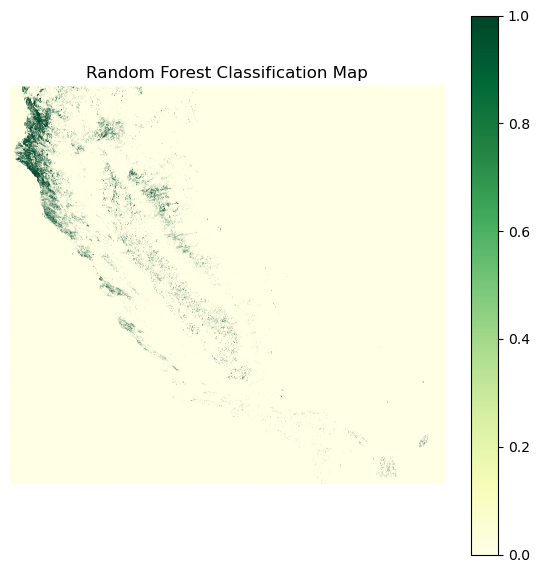

In [108]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,7))
plt.imshow(pred_rf_map, cmap='YlGn')
plt.title("Random Forest Classification Map")
plt.colorbar()
plt.axis('off')
plt.show()

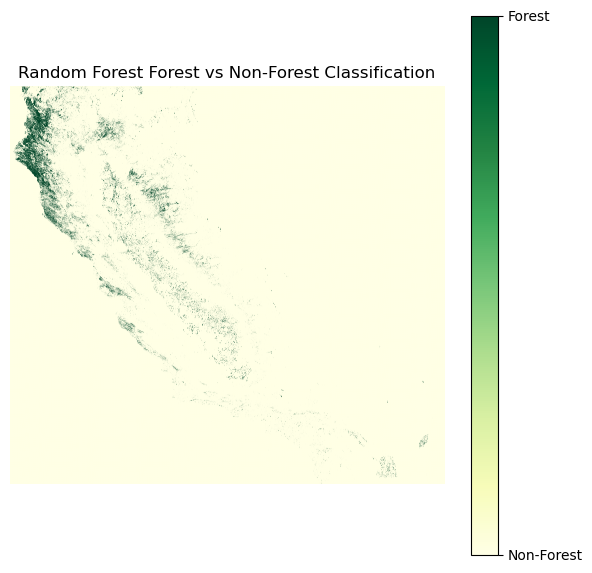

In [110]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,7))

plt.imshow(pred_rf_map, cmap='YlGn')

plt.title("Random Forest Forest vs Non-Forest Classification")

cbar = plt.colorbar()
cbar.set_ticks([0,1])
cbar.set_ticklabels(['Non-Forest','Forest'])

plt.axis('off')

plt.show()